# 05 Segments

**Question:** Which segments perform best, with confidence intervals?

Task 2, step 5: **CTR, CVR, CPA and win rate by region, ad exchange, slot size, slot visibility, browser or device (from the user agent) and user tags**, with **confidence intervals**, and with **segments below a minimum volume hidden**. Slot format and floor-price band are added because they come for free.

**Rules:**
* Clicks and conversions are linked to their impression (bid_id + user + nearest earlier impression), as in Notebook 02. CTR = clicked impressions / impressions. CVR = post-click converted impressions / clicked impressions. CPA = spend / all converted impressions. Win rate = impressions / bids. All are **ratios of sums**.
* **Confidence intervals:** 95% Wilson intervals for CTR, CVR and win rate.
* **Minimum volume** (*why 5 clicks tell you almost nothing*): a CTR's 95% interval is roughly ±2/√clicks of its value. At 5 clicks that is about ±90%, and at 30 clicks about ±36%. So:
  * **CTR** is shown when the segment would expect **≥ 30 clicks at the average CTR** (`min impressions = 30 / CTR`)
  * **CVR** when it has **≥ 30 clicks**, **CPA** when it has **≥ 10 conversions**, **win rate** when it has **≥ 1,000 bids**
* **Is a segment better?** Each segment's CTR is tested against *the rest of its scope* with a two-proportion z-test. With dozens of segments, about 1 in 20 would pass at p < 0.05 by chance (*multiple comparisons*), so a segment only counts as different when it survives the **Benjamini–Hochberg** correction (`q < 0.05`).
* **Correlation ≠ causation:** a high-CTR segment may simply coincide with better users or pages. Confirm with a controlled bid test before moving budget.
* **Scope:** results are shown for *all campaigns pooled* and *per campaign*. Campaigns differ a lot (only some have conversions), so prefer the per-campaign view for decisions. Notebook 09 checks where pooling misleads.

### Setup

In [8]:
# CELL 1: setup (read-only connection)
from pathlib import Path
import math, os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

KILL_STALE = False
RUN_WIN_RATE = True          # win rate needs one pass over the 53M bids (a few minutes)
FOCUS = 1458                 # the campaign shown in detail; change to any advertiser_id
MIN_EXPECTED_CLICKS = 30     # CTR shown when imps >= this / overall CTR
MIN_CLICKS_CVR, MIN_CONVS_CPA, MIN_BIDS_WR = 30, 10, 1_000
TOP_TAGS = 30                # user tags shown (by volume)
PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            m = re.search(r"PID (\d+)", str(e))
            if "lock" not in str(e).lower() or m is None:
                raise
            print(f"The database is locked by another Python process (PID {m.group(1)}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            os.kill(int(m.group(1)), signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")
except Exception:
    pass
q = lambda sql: con.execute(sql).df()

views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
assert {"typed_imp", "typed_clk", "typed_conv"} <= views, "Run the loading cells first"
if "typed_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    t = lambda c, typ="BIGINT": f"TRY_CAST(nullif(nullif({c}, ''), 'null') AS {typ}) AS {c}"
    con.execute("CREATE TEMP VIEW typed_bid AS SELECT " + ", ".join(
        [t(c) for c in ["advertiser_id", "region", "ad_exchange", "ad_slot_width", "ad_slot_height",
                        "ad_slot_visibility", "ad_slot_format", "ad_slot_floor_price"]] + ["user_agent", "user_tags"])
        + " FROM read_parquet([" + ", ".join(f"'{x}'" for x in files) + "])")
    print("typed_bid rebuilt in memory from", len(files), "Parquet files")

# optional readable names, if the dataset's lookup files are anywhere under data/
def lookup(name):
    for p in (PROJECT_ROOT / "data").rglob(name):
        d = {}
        for line in p.read_text(encoding="utf-8", errors="replace").splitlines():
            parts = line.split("\t")
            if len(parts) >= 2 and parts[0].strip().lstrip("-").isdigit():
                d[parts[0].strip()] = parts[1].strip()
        return d
    return {}
REGION_NAMES, TAG_NAMES = lookup("region.en.txt"), lookup("user.profile.tags.en.txt")
print("region names:", "found" if REGION_NAMES else "not found (codes shown)",
      "| tag names:", "found" if TAG_NAMES else "not found (codes shown)")

def wilson(k, n, z=1.959964):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        d = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.where(n > 0, c - h, np.nan), np.where(n > 0, c + h, np.nan)

def ztest(k1, n1, k2, n2):
    """Two-proportion z-test (pooled), two-sided p-value. Returns (z, p)."""
    p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    se = math.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    if se == 0:
        return np.nan, np.nan
    z = (p1 - p2) / se
    return z, math.erfc(abs(z) / math.sqrt(2))

def bh(p):
    """Benjamini-Hochberg q-values (NaN stays NaN)."""
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.sum():
        pv = p[ok]
        o = np.argsort(pv)
        r = pv[o] * ok.sum() / np.arange(1, ok.sum() + 1)
        r = np.minimum.accumulate(r[::-1])[::-1]
        res = np.empty_like(pv)
        res[o] = np.clip(r, 0, 1)
        out[ok] = res
    return out

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mt
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": "#e6e5e0", "axes.titlesize": 10, "axes.titleweight": "bold",
                         "axes.titlelocation": "left", "font.size": 9})
except ImportError:
    plt = None
BLUE, ORANGE, GREY, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"

def save(fig, name):
    try:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except OSError:
        print(f"(no disk space: {name}.png not saved)")
print("Data:", DATA_SOURCE)

region names: found | tag names: found
Data: ipinyou.duckdb (the loading notebook's database)


### 1. Device, OS and browser from the user agent

Each **distinct** user-agent string is parsed once, with simple pattern rules, into a small in-memory lookup table that the logs then join to. Tablets are checked before phones, because iPad strings also contain "Mobile". Chinese browsers common in 2013 (360, Sogou, Maxthon, QQ, TheWorld, UC) are checked before Chrome and IE, because they include those words in their strings.

In [9]:
# CELL 2: user-agent lookup
t0 = time.time()
ua_src = "SELECT DISTINCT user_agent FROM typed_imp" + (" UNION SELECT DISTINCT user_agent FROM typed_bid" if RUN_WIN_RATE else "")
con.execute(f"""
CREATE OR REPLACE TEMP TABLE ua_map AS
WITH u AS ({ua_src}), l AS (SELECT user_agent, lower(coalesce(user_agent, '')) AS ua FROM u)
SELECT user_agent,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'ipad|tablet') THEN 'tablet'
       WHEN regexp_matches(ua, 'mobile|android|iphone|ipod|windows phone|symbian|blackberry|nokia|ucweb|opera mini|midp') THEN 'mobile'
       ELSE 'desktop' END AS device,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'iphone|ipad|ipod') THEN 'iOS'
       WHEN regexp_matches(ua, 'android') THEN 'Android'
       WHEN regexp_matches(ua, 'windows nt 5\\.1|windows xp') THEN 'Windows XP'
       WHEN regexp_matches(ua, 'windows nt 6\\.1') THEN 'Windows 7'
       WHEN regexp_matches(ua, 'windows nt 6\\.[23]') THEN 'Windows 8'
       WHEN regexp_matches(ua, 'windows nt 6\\.0') THEN 'Windows Vista'
       WHEN regexp_matches(ua, 'windows') THEN 'Windows (other)'
       WHEN regexp_matches(ua, 'mac os|macintosh') THEN 'macOS'
       WHEN regexp_matches(ua, 'linux') THEN 'Linux'
       ELSE 'other' END AS os,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'metasr|sogou') THEN 'Sogou'
       WHEN regexp_matches(ua, '360se|360ee|360browser') THEN '360'
       WHEN regexp_matches(ua, 'maxthon') THEN 'Maxthon'
       WHEN regexp_matches(ua, 'theworld') THEN 'TheWorld'
       WHEN regexp_matches(ua, 'qqbrowser|tencenttraveler') THEN 'QQ'
       WHEN regexp_matches(ua, 'ucbrowser|ucweb') THEN 'UC'
       WHEN regexp_matches(ua, 'opera|opr/') THEN 'Opera'
       WHEN regexp_matches(ua, 'chrome|crios') THEN 'Chrome'
       WHEN regexp_matches(ua, 'firefox') THEN 'Firefox'
       WHEN regexp_matches(ua, 'msie|trident') THEN 'IE'
       WHEN regexp_matches(ua, 'safari') THEN 'Safari'
       ELSE 'other' END AS browser
FROM l""")
n_ua = q("SELECT count(*) AS n FROM ua_map").n[0]
print(f"{n_ua:,} distinct user agents parsed ({time.time() - t0:.0f}s)")
display(q("""SELECT device, os, browser, count(*) AS distinct_strings FROM ua_map GROUP BY ALL
             ORDER BY distinct_strings DESC LIMIT 12"""))

1,290,432 distinct user agents parsed (2s)


,device,os,browser,distinct_strings
0,desktop,Windows XP,IE,664300
1,desktop,Windows 7,IE,142271
2,desktop,Windows XP,QQ,86087
3,desktop,Windows XP,Sogou,71608
4,desktop,Windows 7,Sogou,40418
5,desktop,Windows XP,360,28514
6,tablet,Windows 7,IE,27408
7,desktop,Windows XP,TheWorld,23718
8,desktop,Windows 7,QQ,20605
9,desktop,Windows XP,Maxthon,19349


### 2. Link clicks and conversions (the Notebook 02 rule)

The result is a small in-memory table of flags (clicked, converted, converted after a click), keyed by impression.

In [10]:
# CELL 3: linking -> flags per impression
con.execute("""
CREATE OR REPLACE TEMP TABLE imp_c AS
SELECT DISTINCT bid_id, ipinyou_id, timestamp AS imp_ts, hash(bid_id, ipinyou_id, timestamp) AS imp_key
FROM typed_imp WHERE bid_id IN (SELECT bid_id FROM typed_clk UNION SELECT bid_id FROM typed_conv)""")
for log in ["clk", "conv"]:
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE {log}_m AS
    WITH e AS (SELECT row_number() OVER () AS ev_id, bid_id, ipinyou_id, timestamp AS ev_ts
               FROM (SELECT DISTINCT * FROM typed_{log})),
    m1 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i
           ON e.bid_id = i.bid_id AND e.ipinyou_id = i.ipinyou_id AND e.ev_ts >= i.imp_ts),
    m2 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i ON e.bid_id = i.bid_id AND e.ev_ts >= i.imp_ts),
    m3 AS (SELECT e.ev_id, arg_min(i.imp_key, abs(epoch(e.ev_ts) - epoch(i.imp_ts))) AS imp_key
           FROM e JOIN imp_c i USING (bid_id) GROUP BY 1)
    SELECT coalesce(m1.imp_key, m2.imp_key, m3.imp_key) AS imp_key
    FROM e LEFT JOIN m1 USING (ev_id) LEFT JOIN m2 USING (ev_id) LEFT JOIN m3 USING (ev_id)""")
con.execute("""
CREATE OR REPLACE TEMP TABLE flags AS
WITH k AS (SELECT DISTINCT imp_key FROM clk_m WHERE imp_key IS NOT NULL),
     v AS (SELECT DISTINCT imp_key FROM conv_m WHERE imp_key IS NOT NULL)
SELECT coalesce(k.imp_key, v.imp_key) AS imp_key, (k.imp_key IS NOT NULL)::INT AS clicked,
       (v.imp_key IS NOT NULL)::INT AS converted, (k.imp_key IS NOT NULL AND v.imp_key IS NOT NULL)::INT AS pc_converted
FROM k FULL JOIN v USING (imp_key)""")
display(q("SELECT sum(clicked) AS clicked_imps, sum(converted) AS converted_imps, sum(pc_converted) AS postclick_converted FROM flags"))

,clicked_imps,converted_imps,postclick_converted
0,8751.0,391.0,391.0


### 3. Aggregate every segment in one pass per log

`GROUPING SETS` computes every dimension at once, both pooled and per campaign, in a single scan of the impressions and a single scan of the bids. The result is a small table with one row per scope, dimension and segment. User tags are a comma-separated list, so they are split into one row per tag and counted separately. One impression with five tags counts towards five tag segments, so tag segments overlap and don't add up to the total.

In [11]:
# CELL 4: segment aggregates
DIMS = {   # dimension -> SQL expression (same in the impression and bid logs)
    "region": "CAST(region AS VARCHAR)",
    "ad_exchange": "CAST(ad_exchange AS VARCHAR)",
    "slot_size": "CAST(ad_slot_width AS VARCHAR) || 'x' || CAST(ad_slot_height AS VARCHAR)",
    "slot_visibility": "CAST(ad_slot_visibility AS VARCHAR)",
    "slot_format": "CAST(ad_slot_format AS VARCHAR)",
    "floor_band": """CASE WHEN ad_slot_floor_price = 0 THEN 'a: 0' WHEN ad_slot_floor_price <= 10 THEN 'b: 1-10'
                          WHEN ad_slot_floor_price <= 50 THEN 'c: 11-50' WHEN ad_slot_floor_price <= 100 THEN 'd: 51-100'
                          WHEN ad_slot_floor_price <= 200 THEN 'e: 101-200' ELSE 'f: 200+' END""",
    "device": "u.device", "os": "u.os", "browser": "u.browser",
}

def grouped(source, measures, extra_from=""):
    sel = ", ".join(f"{expr} AS {d}" for d, expr in DIMS.items())
    sets = ", ".join(f"(advertiser_id, {d}), ({d})" for d in DIMS)
    gcols = ", ".join(f"GROUPING({d}) AS g_{d}" for d in DIMS)
    return q(f"""
        WITH s AS (SELECT advertiser_id, {sel}, {measures['row']}
                   FROM {source} {extra_from})
        SELECT advertiser_id, {", ".join(DIMS)}, GROUPING(advertiser_id) AS g_adv, {gcols}, {measures['agg']}
        FROM s GROUP BY GROUPING SETS ({sets})""")

def to_long(df, value_cols):
    out = []
    for d in DIMS:
        part = df[df[f"g_{d}"] == 0]
        out.append(pd.DataFrame({"scope": np.where(part.g_adv == 0, part.advertiser_id.astype("Int64").astype(str), "ALL"),
                                 "dimension": d, "segment": part[d].fillna("NULL").astype(str).values,
                                 **{c: part[c].values for c in value_cols}}))
    return pd.concat(out, ignore_index=True)

t0 = time.time()
imp_agg = grouped(
    "typed_imp i",
    {"row": "coalesce(f.clicked, 0) AS clicked, coalesce(f.converted, 0) AS converted, "
            "coalesce(f.pc_converted, 0) AS pc_converted, paying_price / 1000.0 AS cost",
     "agg": "count(*) AS imps, sum(clicked) AS clicks, sum(converted) AS convs, sum(pc_converted) AS pc_convs, sum(cost) AS spend"},
    "LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp) LEFT JOIN ua_map u USING (user_agent)")
seg = to_long(imp_agg, ["imps", "clicks", "convs", "pc_convs", "spend"])
print(f"impression segments: {len(seg):,} rows ({time.time() - t0:.0f}s)")

if RUN_WIN_RATE:
    t0 = time.time()
    bid_agg = grouped("typed_bid b", {"row": "1 AS one", "agg": "count(*) AS bids"},
                      "LEFT JOIN ua_map u USING (user_agent)")
    seg = seg.merge(to_long(bid_agg, ["bids"]), on=["scope", "dimension", "segment"], how="left")
    print(f"bid segments added ({time.time() - t0:.0f}s)")
else:
    seg["bids"] = np.nan

# user tags (impressions only; the bid log has no user tags in Season 2, see Notebook 01)
t0 = time.time()
tags = q("""
    WITH t AS (SELECT i.advertiser_id, unnest(string_split(i.user_tags, ',')) AS tag,
                      coalesce(f.clicked, 0) AS clicked, coalesce(f.converted, 0) AS converted,
                      coalesce(f.pc_converted, 0) AS pc_converted, i.paying_price / 1000.0 AS cost
               FROM typed_imp i LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp)
               WHERE i.user_tags IS NOT NULL)
    SELECT advertiser_id, tag, GROUPING(advertiser_id) AS g_adv, count(*) AS imps, sum(clicked) AS clicks,
           sum(converted) AS convs, sum(pc_converted) AS pc_convs, sum(cost) AS spend
    FROM t GROUP BY GROUPING SETS ((advertiser_id, tag), (tag))""")
tags = pd.DataFrame({"scope": np.where(tags.g_adv == 0, tags.advertiser_id.astype("Int64").astype(str), "ALL"),
                     "dimension": "user_tag", "segment": tags.tag.astype(str),
                     **{c: tags[c].values for c in ["imps", "clicks", "convs", "pc_convs", "spend"]}, "bids": np.nan})
top = tags[tags.scope == "ALL"].nlargest(TOP_TAGS, "imps").segment
seg = pd.concat([seg, tags[tags.segment.isin(top)]], ignore_index=True)
print(f"user tags: {tags.segment.nunique()} distinct, top {TOP_TAGS} kept ({time.time() - t0:.0f}s)")

# scope totals (for 'vs the rest' and the shares)
totals = q("""SELECT CAST(advertiser_id AS VARCHAR) AS scope, count(*) AS imps,
                     sum(coalesce(f.clicked, 0)) AS clicks, sum(paying_price) / 1000.0 AS spend
              FROM typed_imp i LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp)
              GROUP BY ROLLUP (advertiser_id)""")
totals["scope"] = totals.scope.fillna("ALL")
totals = totals.set_index("scope")
display(totals.style.format({"imps": "{:,.0f}", "clicks": "{:,.0f}", "spend": "{:,.0f}"}))

impression segments: 542 rows (1s)
bid segments added (24s)
user tags: 43 distinct, top 30 kept (1s)


,imps,clicks,spend
scope,,,
3427,"2,593,765","1,909","210,240"
ALL,"12,237,087","8,751","958,739"
3386,"2,847,802","2,062","219,067"
1458,"3,083,056","2,434","212,400"
3476,"1,970,360","1,023","156,088"
3358,"1,742,104","1,323","160,943"


### 4. KPIs, confidence intervals, the volume rule and significance

In [12]:
# CELL 5: metrics per segment
S = seg.copy()
for c in ["imps", "clicks", "convs", "pc_convs"]:
    S[c] = S[c].fillna(0).astype("int64")
S["imp_share"] = S.imps / S.scope.map(totals.imps)
S["ctr"] = S.clicks / S.imps
S["ctr_lo"], S["ctr_hi"] = wilson(S.clicks, S.imps)
S["cvr"] = S.pc_convs / S.clicks.where(S.clicks > 0)
S["cvr_lo"], S["cvr_hi"] = wilson(S.pc_convs, S.clicks)
S["cpa"] = S.spend / S.convs.where(S.convs > 0)
S["cpm"] = 1000 * S.spend / S.imps
S["cpc"] = S.spend / S.clicks.where(S.clicks > 0)
S["win_rate"] = S.imps / S.bids.where(S.bids > 0)
S["win_rate_lo"], S["win_rate_hi"] = wilson(S.imps, S.bids)

# minimum volume, per scope (each campaign has its own CTR)
scope_ctr = totals.clicks / totals.imps
S["min_imps"] = np.ceil(MIN_EXPECTED_CLICKS / S.scope.map(scope_ctr))
S["show_ctr"] = S.imps >= S.min_imps
S["show_cvr"] = S.clicks >= MIN_CLICKS_CVR
S["show_cpa"] = S.convs >= MIN_CONVS_CPA
S["show_wr"] = S.bids >= MIN_BIDS_WR

# segment vs the rest of its scope (CTR), then Benjamini-Hochberg over every test run
res = [ztest(r.clicks, r.imps, totals.clicks[r.scope] - r.clicks, totals.imps[r.scope] - r.imps)
       if r.show_ctr and 0 < r.imps < totals.imps[r.scope] else (np.nan, np.nan) for r in S.itertuples()]
S["z_vs_rest"], S["p_vs_rest"] = [x[0] for x in res], [x[1] for x in res]
rest_ctr = (S.scope.map(totals.clicks) - S.clicks) / (S.scope.map(totals.imps) - S.imps)
S["ctr_lift_vs_rest"] = S.ctr / rest_ctr - 1
S["q_vs_rest"] = bh(S.p_vs_rest)
S["significant"] = S.q_vs_rest < 0.05

S["label"] = [f"{s} · {REGION_NAMES.get(s, '')}" if d == "region" and s in REGION_NAMES else
              (f"{s} · {TAG_NAMES.get(s, '')}" if d == "user_tag" and s in TAG_NAMES else s)
              for d, s in zip(S.dimension, S.segment)]

n_tests = int(S.p_vs_rest.notna().sum())
mc = pd.DataFrame({"tests run": [int(n_tests)], "p < 0.05 (uncorrected)": [int((S.p_vs_rest < 0.05).sum())],
                   "expected by chance at 5%": [round(0.05 * n_tests, 1)],
                   "q < 0.05 (Benjamini–Hochberg)": [int(S.significant.sum())]})
print("Multiple comparisons: how many 'winners' would appear by chance?")
display(mc)
hidden = S[~S.show_ctr]
print(f"Hidden for low volume (CTR): {len(hidden):,} of {len(S):,} segment rows")

try:
    S.to_csv(PROJECT_ROOT / "data" / "processed" / "segments.csv", index=False)
    print("Saved data/processed/segments.csv")
except OSError:
    print("(no disk space: segments.csv not saved)")

Multiple comparisons: how many 'winners' would appear by chance?


,tests run,p < 0.05 (uncorrected),expected by chance at 5%,q < 0.05 (Benjamini–Hochberg)
0,481,295,24.1,279


Hidden for low volume (CTR): 241 of 722 segment rows
Saved data/processed/segments.csv


### 5. Segment tables

For each dimension: all campaigns pooled, then the focus campaign (`FOCUS`). Columns with too little volume show "–". `q` is the corrected significance of the CTR difference against the rest of the scope. Read **lift** together with its interval: a +40% lift with a CI spanning zero is not a finding.

In [13]:
# CELL 6: tables per dimension (pooled and focus campaign)
COLS = ["label", "bids", "imps", "imp_share", "clicks", "ctr", "ctr_lo", "ctr_hi", "ctr_lift_vs_rest", "q_vs_rest",
        "win_rate", "convs", "cvr", "cpa", "cpm"]
F = {"bids": "{:,.0f}", "imps": "{:,.0f}", "imp_share": "{:.1%}", "clicks": "{:,.0f}", "ctr": "{:.3%}",
     "ctr_lo": "{:.3%}", "ctr_hi": "{:.3%}", "ctr_lift_vs_rest": "{:+.0%}", "q_vs_rest": "{:.2g}",
     "win_rate": "{:.1%}", "convs": "{:,.0f}", "cvr": "{:.1%}", "cpa": "{:,.0f}", "cpm": "{:.1f}"}

def show_table(scope, dim):
    t = S[(S.scope == scope) & (S.dimension == dim)].sort_values("imps", ascending=False).copy()
    for c in ["ctr", "ctr_lo", "ctr_hi", "ctr_lift_vs_rest", "q_vs_rest"]:
        t[c] = t[c].where(t.show_ctr)
    t["cvr"], t["cpa"], t["win_rate"] = t.cvr.where(t.show_cvr), t.cpa.where(t.show_cpa), t.win_rate.where(t.show_wr)
    shown = t[t.show_ctr]
    n_hidden = len(t) - len(shown)
    return shown[COLS], n_hidden

for dim in list(DIMS) + ["user_tag"]:
    for scope in ["ALL", str(FOCUS)]:
        t, n_hidden = show_table(scope, dim)
        display(Markdown(f"**{dim.replace('_', ' ')}: {'all campaigns' if scope == 'ALL' else 'campaign ' + scope}**"
                         f" ({len(t)} shown, {n_hidden} hidden for low volume)"))
        display(t.style.format(F, na_rep="–").hide(axis="index"))

**region: all campaigns** (31 shown, 4 hidden for low volume)

label,bids,imps,imp_share,clicks,ctr,ctr_lo,ctr_hi,ctr_lift_vs_rest,q_vs_rest,win_rate,convs,cvr,cpa,cpm
216 · guangdong,"8,190,271","1,492,990",12.2%,936,0.063%,0.059%,0.067%,-14%,4.2e-05,18.2%,46,4.9%,"2,528",77.9
80 · jiangsu,"4,821,527","1,015,169",8.3%,666,0.066%,0.061%,0.071%,-9%,0.035,21.1%,35,5.3%,"2,247",77.5
146 · shandong,"4,189,952","866,063",7.1%,656,0.076%,0.070%,0.082%,+6%,0.19,20.7%,30,4.6%,"2,262",78.4
94 · zhejiang,"3,612,295","696,906",5.7%,495,0.071%,0.065%,0.078%,-1%,0.9,19.3%,18,3.6%,"3,133",80.9
276 · sichuan,"2,478,257","689,805",5.6%,413,0.060%,0.054%,0.066%,-17%,0.00046,27.8%,16,3.9%,"3,044",70.6
3 · hebei,"2,696,591","585,992",4.8%,465,0.079%,0.072%,0.087%,+12%,0.038,21.7%,12,2.6%,"3,888",79.6
164 · henan,"2,264,187","578,962",4.7%,418,0.072%,0.066%,0.079%,+1%,0.88,25.6%,21,5.0%,"2,242",81.3
1 · beijing,"1,411,204","552,155",4.5%,397,0.072%,0.065%,0.079%,+1%,0.93,39.1%,17,4.3%,"2,578",79.4
183 · hubei,"1,817,819","437,200",3.6%,307,0.070%,0.063%,0.079%,-2%,0.79,24.1%,12,3.9%,"2,930",80.4
40 · liaoning,"1,534,917","434,115",3.5%,286,0.066%,0.059%,0.074%,-8%,0.22,28.3%,9,3.1%,–,77.3


**region: campaign 1458** (26 shown, 9 hidden for low volume)

label,bids,imps,imp_share,clicks,ctr,ctr_lo,ctr_hi,ctr_lift_vs_rest,q_vs_rest,win_rate,convs,cvr,cpa,cpm
216 · guangdong,"2,169,920","359,037",11.6%,242,0.067%,0.059%,0.076%,-16%,0.017,16.5%,0,0.0%,–,68.5
80 · jiangsu,"1,345,596","249,896",8.1%,189,0.076%,0.066%,0.087%,-5%,0.63,18.6%,0,0.0%,–,68.1
146 · shandong,"1,356,890","231,274",7.5%,189,0.082%,0.071%,0.094%,+4%,0.7,17.0%,0,0.0%,–,68.3
94 · zhejiang,"1,042,042","175,800",5.7%,130,0.074%,0.062%,0.088%,-7%,0.54,16.9%,0,0.0%,–,72.6
276 · sichuan,"600,615","166,706",5.4%,126,0.076%,0.063%,0.090%,-4%,0.69,27.8%,0,0.0%,–,62.8
3 · hebei,"857,847","155,569",5.0%,139,0.089%,0.076%,0.105%,+14%,0.2,18.1%,0,0.0%,–,69.5
164 · henan,"637,379","152,500",4.9%,127,0.083%,0.070%,0.099%,+6%,0.63,23.9%,0,0.0%,–,69.6
1 · beijing,"312,441","133,809",4.3%,104,0.078%,0.064%,0.094%,-2%,0.9,42.8%,0,0.0%,–,72.5
40 · liaoning,"447,211","116,519",3.8%,84,0.072%,0.058%,0.089%,-9%,0.49,26.1%,0,0.0%,–,67.0
183 · hubei,"500,675","109,983",3.6%,69,0.063%,0.050%,0.079%,-21%,0.083,22.0%,0,0.0%,–,69.9


**ad exchange: all campaigns** (3 shown, 0 hidden for low volume)

label,bids,imps,imp_share,clicks,ctr,ctr_lo,ctr_hi,ctr_lift_vs_rest,q_vs_rest,win_rate,convs,cvr,cpa,cpm
3,"34,026,044","4,396,359",35.9%,"3,187",0.072%,0.070%,0.075%,+2%,0.43,12.9%,81,2.5%,"3,488",64.3
2,"13,145,956","3,962,486",32.4%,"2,141",0.054%,0.052%,0.056%,-32%,2.1e-55,30.1%,90,4.2%,"3,390",77.0
1,"6,117,330","3,878,242",31.7%,"3,423",0.088%,0.085%,0.091%,+38%,2.1e-49,63.4%,220,6.4%,"1,687",95.7


... (30 outputs left out)

**user tag: all campaigns** (30 shown, 0 hidden for low volume)

label,bids,imps,imp_share,clicks,ctr,ctr_lo,ctr_hi,ctr_lift_vs_rest,q_vs_rest,win_rate,convs,cvr,cpa,cpm
10063 · Long-term interest/entertainment,–,"7,879,044",64.4%,"4,658",0.059%,0.057%,0.061%,-37%,3.4e-104,–,169,3.6%,"3,581",76.8
10006 · Long-term interest/news,–,"7,507,811",61.4%,"4,164",0.055%,0.054%,0.057%,-43%,5.4e-153,–,164,3.9%,"3,466",75.7
10110 · Demographic/gender/male,–,"5,573,855",45.5%,"3,469",0.062%,0.060%,0.064%,-21%,8.7e-28,–,118,3.4%,"3,580",75.8
10083 · Long-term interest/sports,–,"3,064,760",25.0%,"1,664",0.054%,0.052%,0.057%,-30%,7.7e-38,–,53,3.2%,"4,309",74.5
10024 · Long-term interest/eduation,–,"2,882,622",23.6%,"1,600",0.056%,0.053%,0.058%,-27%,2.2e-30,–,66,4.1%,"3,508",80.3
10111 · Demographic/gender/famale,–,"2,681,982",21.9%,"2,602",0.097%,0.093%,0.101%,+51%,7e-69,–,70,2.7%,"2,904",75.8
10059 · Long-term interest/fashion,–,"2,570,620",21.0%,"1,292",0.050%,0.048%,0.053%,-35%,1.1e-45,–,43,3.3%,"4,506",75.4
10031 · Long-term interest/automobile,–,"2,448,849",20.0%,"1,403",0.057%,0.054%,0.060%,-24%,6.8e-20,–,59,4.2%,"3,199",77.1
10075 · Long-term interest/health,–,"2,359,395",19.3%,"1,229",0.052%,0.049%,0.055%,-32%,1.6e-34,–,48,3.9%,"3,861",78.5
10057 · Long-term interest/electronic game,–,"2,321,395",19.0%,"1,307",0.056%,0.053%,0.059%,-25%,3.2e-21,–,44,3.4%,"3,974",75.3


**user tag: campaign 1458** (26 shown, 4 hidden for low volume)

label,bids,imps,imp_share,clicks,ctr,ctr_lo,ctr_hi,ctr_lift_vs_rest,q_vs_rest,win_rate,convs,cvr,cpa,cpm
10063 · Long-term interest/entertainment,–,"1,914,682",62.1%,"1,306",0.068%,0.065%,0.072%,-29%,4.1e-17,–,1,0.1%,–,68.2
10006 · Long-term interest/news,–,"1,881,515",61.0%,"1,201",0.064%,0.060%,0.068%,-38%,2.2e-31,–,1,0.1%,–,66.8
10110 · Demographic/gender/male,–,"1,275,530",41.4%,596,0.047%,0.043%,0.051%,-54%,3.6e-63,–,0,0.0%,–,65.4
10111 · Demographic/gender/famale,–,"818,050",26.5%,"1,446",0.177%,0.168%,0.186%,+305%,3.6e-294,–,1,0.1%,–,67.9
10024 · Long-term interest/eduation,–,"683,218",22.2%,470,0.069%,0.063%,0.075%,-16%,0.0015,–,0,0.0%,–,73.3
10083 · Long-term interest/sports,–,"663,876",21.5%,414,0.062%,0.057%,0.069%,-25%,1.7e-07,–,0,0.0%,–,67.6
13866 · Long-term interest/online literature,–,"642,226",20.8%,494,0.077%,0.070%,0.084%,-3%,0.61,–,1,0.2%,–,65.7
10059 · Long-term interest/fashion,–,"629,220",20.4%,363,0.058%,0.052%,0.064%,-32%,6.5e-11,–,0,0.0%,–,67.4
10075 · Long-term interest/health,–,"562,089",18.2%,342,0.061%,0.055%,0.068%,-27%,2.7e-07,–,0,0.0%,–,69.4
10031 · Long-term interest/automobile,–,"534,940",17.4%,328,0.061%,0.055%,0.068%,-26%,1.2e-06,–,0,0.0%,–,68.5


### 6. CTR by segment with 95% intervals (forest plots)

One panel per dimension. Blue segments differ from the rest *after* the multiple-comparison correction; grey ones are within noise. The dashed line is the scope's overall CTR.

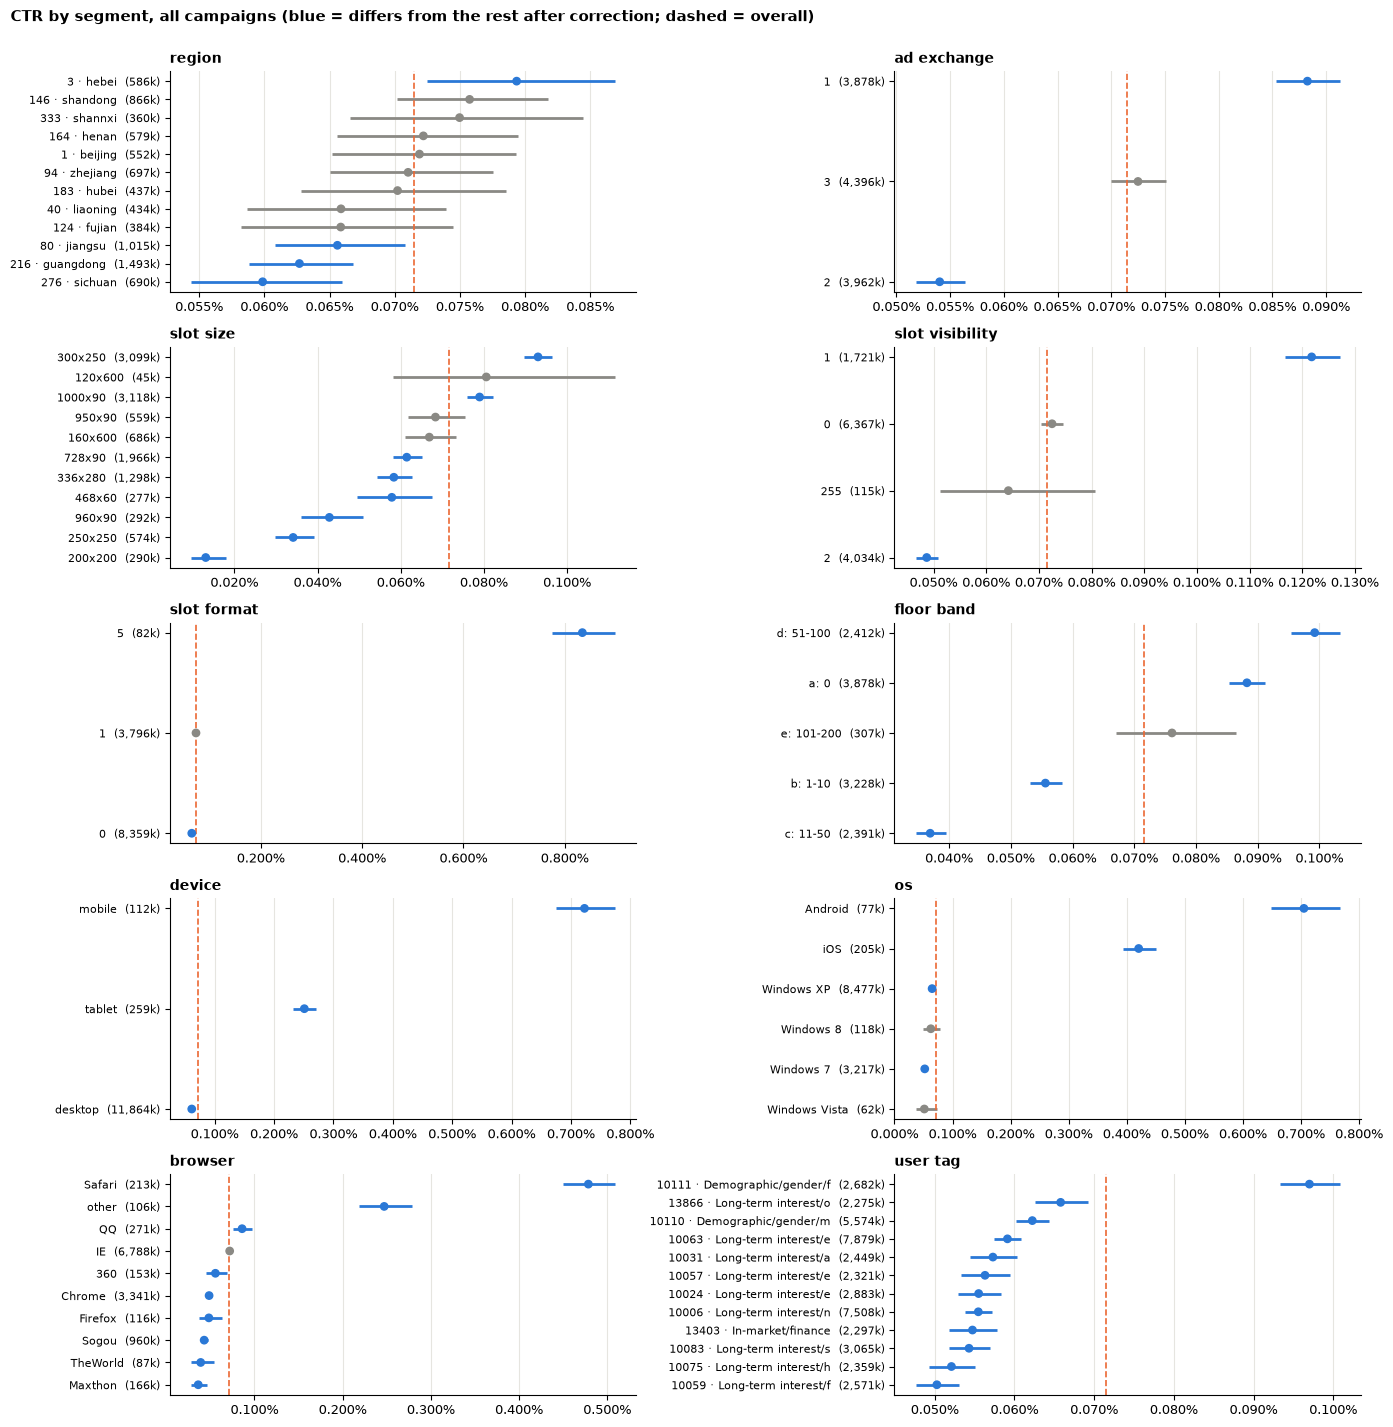

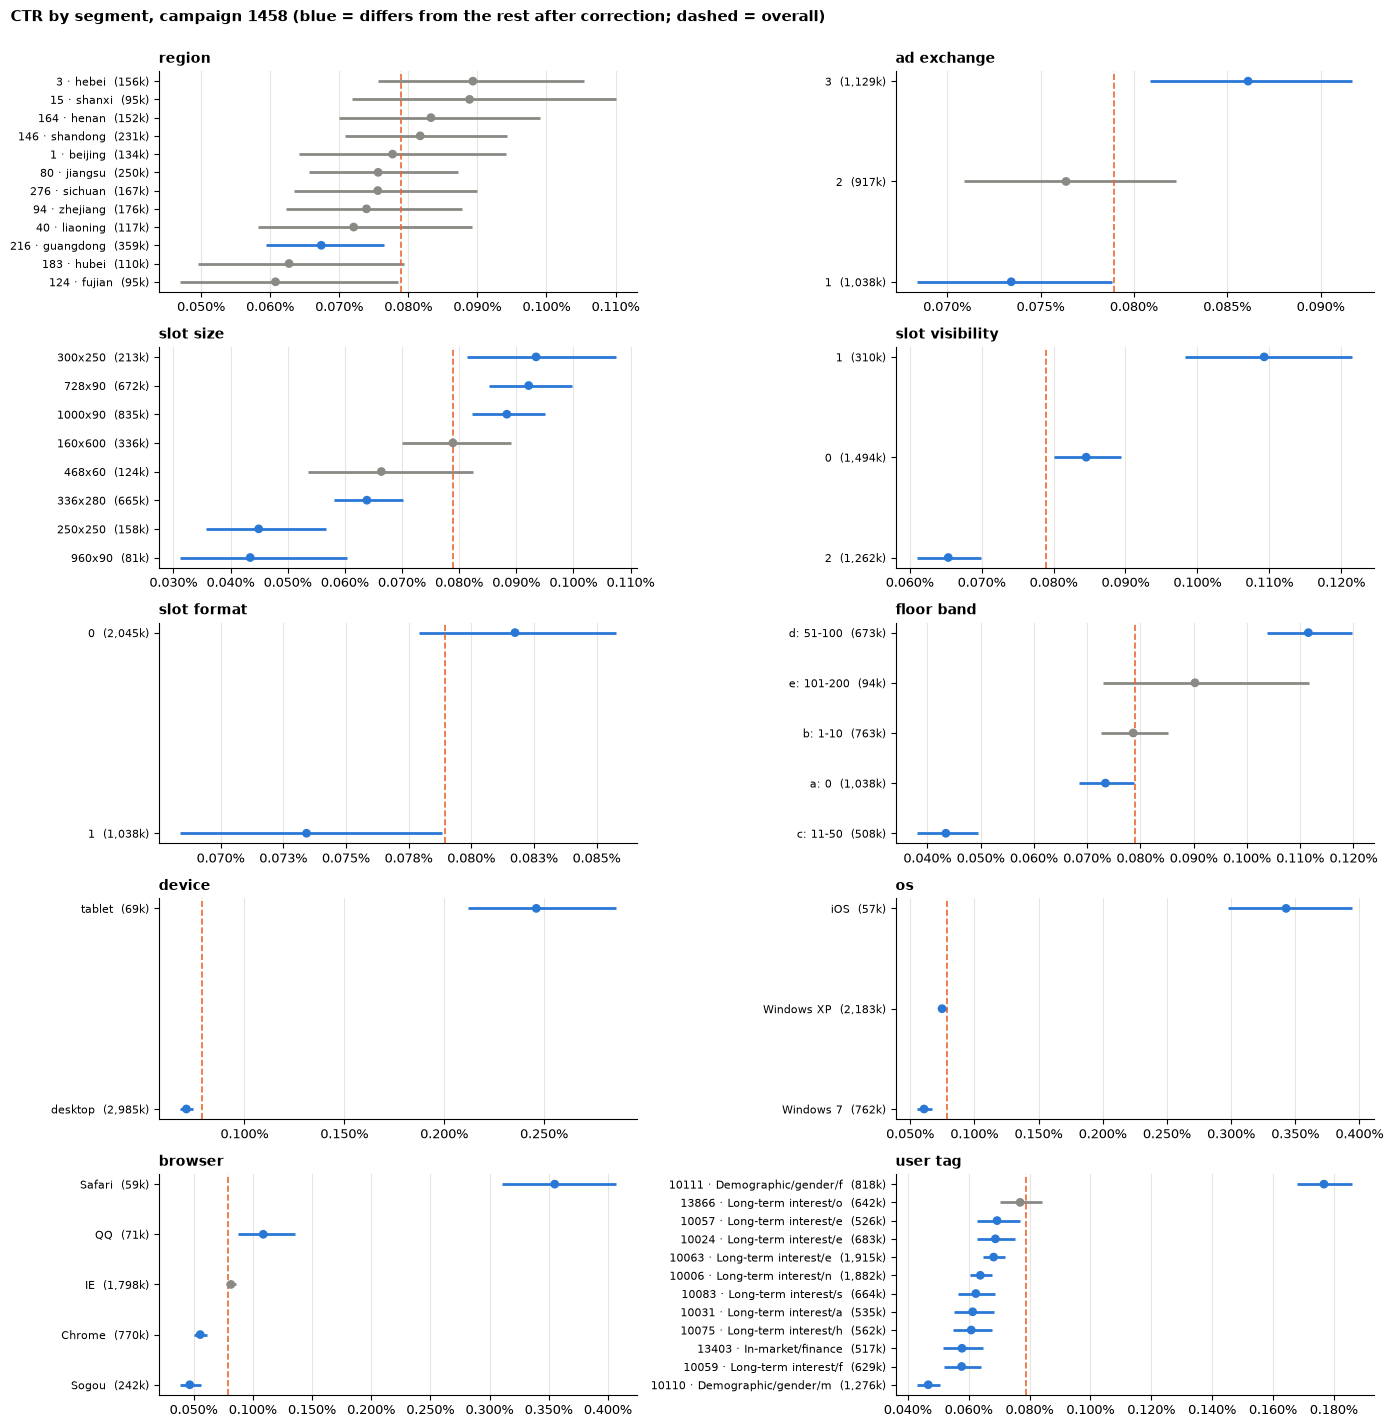

In [14]:
# CELL 7: forest plots (pooled), then the same for the focus campaign
def forest(scope, top=12):
    dims = list(DIMS) + ["user_tag"]
    if not plt:
        return
    fig, axes = plt.subplots(int(np.ceil(len(dims) / 2)), 2, figsize=(14, 2.9 * np.ceil(len(dims) / 2)))
    for ax, dim in zip(axes.flat, dims):
        t = S[(S.scope == scope) & (S.dimension == dim) & S.show_ctr].nlargest(top, "imps").sort_values("ctr")
        if t.empty:
            ax.set_axis_off()
            continue
        y = np.arange(len(t))
        col = np.where(t.significant, BLUE, GREY)
        ax.hlines(y, t.ctr_lo, t.ctr_hi, color=col, lw=2)
        ax.scatter(t.ctr, y, color=col, s=28, zorder=3)
        ax.axvline(scope_ctr[scope], color=ORANGE, ls="--", lw=1.2)
        ax.set_yticks(y, [f"{l[:28]}  ({n / 1e3:,.0f}k)" for l, n in zip(t.label, t.imps)], fontsize=8)
        ax.xaxis.set_major_formatter(mt.PercentFormatter(1.0, decimals=3))
        ax.grid(axis="y", visible=False)
        ax.set_title(dim.replace("_", " "))
    for ax in axes.flat[len(dims):]:
        ax.set_axis_off()
    fig.suptitle(f"CTR by segment, {'all campaigns' if scope == 'ALL' else 'campaign ' + scope} "
                 "(blue = differs from the rest after correction; dashed = overall)",
                 x=0.01, ha="left", fontweight="bold", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    save(fig, f"05_forest_{scope}")
    plt.show()

forest("ALL")
forest(str(FOCUS))

### 7. Every campaign side by side

CTR per segment per campaign, for the main dimensions. "–" means below the minimum volume for that campaign. CVR and CPA are only meaningful for campaigns with conversions (see Notebook 02).

In [15]:
# CELL 8: CTR / win rate / CVR pivots across campaigns
for dim in ["ad_exchange", "slot_visibility", "device", "browser", "slot_size", "floor_band"]:
    t = S[(S.dimension == dim) & S.show_ctr & (S.scope != "ALL")]
    keep = S[(S.dimension == dim) & (S.scope == "ALL")].nlargest(10, "imps").segment
    p = t[t.segment.isin(keep)].pivot_table(index="segment", columns="scope", values="ctr")
    display(Markdown(f"**CTR by {dim.replace('_', ' ')}, per campaign**"))
    display(p.style.format("{:.3%}", na_rep="–"))
    if RUN_WIN_RATE:
        w = S[(S.dimension == dim) & S.show_wr & (S.scope != "ALL") & S.segment.isin(keep)] \
            .pivot_table(index="segment", columns="scope", values="win_rate")
        display(Markdown(f"*win rate by {dim.replace('_', ' ')}*"))
        display(w.style.format("{:.1%}", na_rep="–"))
conv_scopes = [s for s in totals.index if s != "ALL" and S[(S.scope == s) & (S.dimension == "ad_exchange")].convs.sum() >= MIN_CONVS_CPA]
for s in conv_scopes:
    display(Markdown(f"**Campaign {s}: CVR and CPA by segment** (only segments with ≥ {MIN_CLICKS_CVR} clicks / ≥ {MIN_CONVS_CPA} conversions)"))
    t = S[(S.scope == s) & S.show_cvr & (S.dimension != "user_tag")].sort_values(["dimension", "imps"], ascending=[True, False])
    display(t[["dimension", "label", "clicks", "pc_convs", "convs", "cvr", "cvr_lo", "cvr_hi", "cpa"]]
            .assign(cpa=lambda d: d.cpa.where(S.show_cpa))
            .style.format({"cvr": "{:.1%}", "cvr_lo": "{:.1%}", "cvr_hi": "{:.1%}", "cpa": "{:,.0f}"}, na_rep="–")
            .hide(axis="index"))

**CTR by ad exchange, per campaign**

scope,1458,3358,3386,3427,3476
segment,,,,,
1,0.073%,0.093%,0.125%,0.102%,0.047%
2,0.076%,0.046%,0.054%,0.051%,0.033%
3,0.086%,0.078%,0.057%,0.074%,0.073%


*win rate by ad exchange*

scope,1458,3358,3386,3427,3476
segment,,,,,
1,82.3%,53.1%,64.0%,61.5%,58.5%
2,38.8%,51.6%,61.6%,12.7%,61.2%
3,10.2%,29.6%,10.7%,17.2%,15.9%


**CTR by slot visibility, per campaign**

scope,1458,3358,3386,3427,3476
segment,,,,,
0,0.085%,0.083%,0.064%,0.071%,0.063%
1,0.109%,0.113%,0.162%,0.134%,0.070%
2,0.065%,0.046%,0.042%,0.046%,0.030%


... (18 outputs left out)

**Campaign 3476: CVR and CPA by segment** (only segments with ≥ 30 clicks / ≥ 10 conversions)

dimension,label,clicks,pc_convs,convs,cvr,cvr_lo,cvr_hi,cpa
ad_exchange,3,540,16,16,3.0%,1.8%,4.8%,"3,358"
ad_exchange,2,222,6,6,2.7%,1.2%,5.8%,–
ad_exchange,1,261,4,4,1.5%,0.6%,3.9%,–
browser,IE,637,8,8,1.3%,0.6%,2.5%,–
browser,Chrome,215,12,12,5.6%,3.2%,9.5%,"3,817"
browser,Sogou,76,3,3,3.9%,1.4%,11.0%,–
device,desktop,986,26,26,2.6%,1.8%,3.8%,"5,922"
floor_band,a: 0,261,4,4,1.5%,0.6%,3.9%,–
floor_band,b: 1-10,186,4,4,2.2%,0.8%,5.4%,–
floor_band,c: 11-50,211,9,9,4.3%,2.3%,7.9%,–


**Campaign 3358: CVR and CPA by segment** (only segments with ≥ 30 clicks / ≥ 10 conversions)

dimension,label,clicks,pc_convs,convs,cvr,cvr_lo,cvr_hi,cpa
ad_exchange,1,846,216,216,25.5%,22.7%,28.6%,456
ad_exchange,2,247,83,83,33.6%,28.0%,39.7%,501
ad_exchange,3,230,65,65,28.3%,22.8%,34.4%,319
browser,IE,570,189,189,33.2%,29.4%,37.1%,449
browser,Chrome,281,102,102,36.3%,30.9%,42.1%,466
browser,Sogou,47,12,12,25.5%,15.3%,39.5%,912
browser,Safari,268,21,21,7.8%,5.2%,11.7%,261
browser,QQ,35,5,5,14.3%,6.3%,29.4%,–
browser,other,72,21,21,29.2%,19.9%,40.5%,115
device,desktop,947,313,313,33.1%,30.1%,36.1%,484


In [16]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

## Findings

Generated from the numbers above.

In [17]:
# CELL 9: findings
A = S[(S.scope == "ALL") & S.show_ctr & S.p_vs_rest.notna()]
sig = A[A.significant]
Fd = []
if len(sig):
    for dim in sig.sort_values("q_vs_rest").dimension.unique()[:3]:
        d = A[A.dimension == dim].sort_values("ctr")
        lo, hi = d.iloc[0], d.iloc[-1]
        ns = lambda r: "" if r.significant else ", not significant"
        Fd.append(f"**{dim.replace('_', ' ').capitalize()}:** {hi.label} has the highest CTR, {hi.ctr:.3%} (95% CI "
                  f"{hi.ctr_lo:.3%}–{hi.ctr_hi:.3%}, {hi.ctr_lift_vs_rest:+.0%} vs the rest, q = {hi.q_vs_rest:.2g}{ns(hi)}); "
                  f"{lo.label} has the lowest, {lo.ctr:.3%} ({lo.ctr_lo:.3%}–{lo.ctr_hi:.3%}, {lo.ctr_lift_vs_rest:+.0%}, "
                  f"q = {lo.q_vs_rest:.2g}{ns(lo)}).")
fo = S[(S.scope == str(FOCUS)) & S.show_ctr & S.significant]
dev = S[(S.scope == "ALL") & (S.dimension == "device")].set_index("segment")
mob = dev.reindex(["mobile", "tablet"]).imps.sum() / dev.imps.sum() if len(dev) else np.nan
wr = S[(S.scope == "ALL") & S.show_wr & (S.dimension == "ad_exchange")]
F = [
    f"**Testing before calling a segment better.** {int(mc.iloc[0]['tests run']):,} segment-vs-rest CTR tests; "
    f"{int(mc.iloc[0]['p < 0.05 (uncorrected)'])} had p < 0.05, but about {mc.iloc[0]['expected by chance at 5%']:.0f} would "
    f"by chance alone. {int(mc.iloc[0]['q < 0.05 (Benjamini–Hochberg)'])} survive the Benjamini–Hochberg correction. "
    f"Segments under the minimum volume ({int(scope_ctr['ALL'] and MIN_EXPECTED_CLICKS / scope_ctr['ALL']):,} impressions "
    f"pooled) are hidden.",
    *Fd,
    f"**Campaign {FOCUS}:** {len(fo)} segments differ significantly from the rest of the campaign" +
    (": " + "; ".join(f"{r.dimension.replace('_', ' ')} {r.label} {r.ctr_lift_vs_rest:+.0%}" for r in
                      fo.sort_values("q_vs_rest").head(4).itertuples()) if len(fo) else "") + ".",
    f"**Device mix.** Mobile and tablet are {mob:.1%} of impressions"
    + (", so device comparisons rest on a small mobile sample (see the intervals)." if mob < 0.10 else "."),
]
if RUN_WIN_RATE and len(wr):
    spread = wr.win_rate.max() - wr.win_rate.min()
    F.append("**Win rate by ad exchange:** " + "; ".join(f"exchange {r.segment}: {r.win_rate:.1%}" for r in wr.itertuples())
             + (". The exchanges differ in how often we win, not only in CTR." if spread > 0.02
                else ". Win rates are similar across exchanges."))
F.append("**Caveat.** These are correlations: a segment's CTR also reflects which campaigns and pages buy into it. "
         "Notebook 09 checks whether any pooled difference reverses within campaigns.")
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
if len(sig):
    dim0 = sig.sort_values("q_vs_rest").dimension.iloc[0]
    d0 = A[A.dimension == dim0].sort_values("ctr")
    lo0, hi0 = d0.iloc[0], d0.iloc[-1]
    if plt:   # a single-panel chart of the strongest dimension, readable at story size
        t0 = A[A.dimension == dim0].nlargest(12, "imps").sort_values("ctr")
        fig, ax = plt.subplots(figsize=(7, 0.32 * len(t0) + 1.3))
        yy = np.arange(len(t0))
        cc = np.where(t0.significant, BLUE, GREY)
        ax.hlines(yy, t0.ctr_lo, t0.ctr_hi, color=cc, lw=2.5)
        ax.scatter(t0.ctr, yy, color=cc, s=36, zorder=3)
        ax.axvline(scope_ctr["ALL"], color=ORANGE, ls="--", lw=1.2)
        ax.set_yticks(yy, [f"{l[:24]}  ({n / 1e3:,.0f}k)" for l, n in zip(t0.label, t0.imps)])
        ax.xaxis.set_major_formatter(mt.PercentFormatter(1.0, decimals=3))
        ax.grid(axis="y", visible=False)
        ax.set_title(f"CTR by {dim0.replace('_', ' ')} with 95% CI (blue = differs after correction; dashed = overall)")
        fig.tight_layout()
        save(fig, "05_top_dimension")
        plt.close(fig)
    save_story("05_segments", [{
        "title": f"{dim0.replace('_', ' ').capitalize()} drives CTR: {hi0.label} vs {lo0.label}",
        "number": f"{hi0.label} {hi0.ctr:.3%} (95% CI {hi0.ctr_lo:.3%}–{hi0.ctr_hi:.3%}, {hi0.ctr_lift_vs_rest:+.0%} vs rest) "
                  f"vs {lo0.label} {lo0.ctr:.3%} ({lo0.ctr_lift_vs_rest:+.0%}); {int(mc.iloc[0]['q < 0.05 (Benjamini–Hochberg)'])} of "
                  f"{int(mc.iloc[0]['tests run'])} segment tests survive the multiple-comparison correction",
        "chart": "05_top_dimension.png",
        "confidence": "High (q < 0.001)" if min(hi0.q_vs_rest, lo0.q_vs_rest) < 0.001 else
                      f"Medium (q = {min(hi0.q_vs_rest, lo0.q_vs_rest):.2g})",
        "meaning": f"Shift budget toward {hi0.label} and test a lower bid on {lo0.label}. This is a correlation, so "
                   "confirm with a controlled bid test.",
    }])

1. **Testing before calling a segment better.** 481 segment-vs-rest CTR tests; 295 had p < 0.05, but about 24 would by chance alone. 279 survive the Benjamini–Hochberg correction. Segments under the minimum volume (41,950 impressions pooled) are hidden.
2. **Browser:** Safari has the highest CTR, 0.479% (95% CI 0.450%–0.509%, +644% vs the rest, q = 0); Maxthon has the lowest, 0.036% (0.028%–0.047%, -50%, q = 1.8e-07).
3. **Os:** Android has the highest CTR, 0.705% (95% CI 0.648%–0.767%, +944% vs the rest, q = 0); Windows Vista has the lowest, 0.051% (0.036%–0.073%, -28%, q = 0.095, not significant).
4. **Device:** mobile has the highest CTR, 0.723% (95% CI 0.675%–0.774%, +1003% vs the rest, q = 0); desktop has the lowest, 0.061% (0.060%–0.063%, -84%, q = 0).
5. **Campaign 1458:** 44 segments differ significantly from the rest of the campaign: user tag 10111 · Demographic/gender/famale +305%; device desktop -78%; browser Safari +383%; os iOS +363%.
6. **Device mix.** Mobile and tablet are 3.0% of impressions, so device comparisons rest on a small mobile sample (see the intervals).
7. **Win rate by ad exchange:** exchange 2: 30.1%; exchange 3: 12.9%; exchange 1: 63.4%. The exchanges differ in how often we win, not only in CTR.
8. **Caveat.** These are correlations: a segment's CTR also reflects which campaigns and pages buy into it. Notebook 09 checks whether any pooled difference reverses within campaigns.

Saved 1 story candidate(s) to reports/findings/05_segments.json
